# 09 - Interpolação
Vamos aprender sobre como usar aproximação de funções que permite construir um novo conjunto de dados a partir de um conjunto discreto de dados pontuais previamente conhecidos.

Crie uma nova branch (versão) do repositório:

```bash
git branch semana9
```

Faça o checkout nessa nova branch:

```bash
git checkout semana9
```

<hr />

## Atividade 1
Escreva os métodos de Newton, Lagrange, polinomial dentro do arquivo $utils/algoritmos.py$.

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join('..')))
from scipy.interpolate import CubicSpline

from utils.algoritmos import newton, lagrange, polinomial


def interpolar(x, y, xr, bc="natural", titulo=""):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    xr = np.asarray(xr, dtype=float)
    metodos = {
        "Newton": newton(x, y),
        "Lagrange": lagrange(x, y),
        "Polinomial": polinomial(x, y),
    }
    spline = CubicSpline(x, y, bc_type=bc)
    for nome, p in metodos.items():
        print(f"{nome}: {np.round(p, 6)}")
        print(f"  f({xr}) = {np.polyval(p, xr)}")
    print(f"Spline cúbica: f({xr}) = {spline(xr)}")

    xs = np.linspace(x.min() - 0.25, x.max() + 0.25, 400)
    plt.figure(figsize=(8, 5))
    plt.plot(xs, np.polyval(metodos["Newton"], xs), label="Newton")
    plt.plot(xs, np.polyval(metodos["Lagrange"], xs), "--", label="Lagrange")
    plt.plot(xs, np.polyval(metodos["Polinomial"], xs), ":", label="Polinomial")
    plt.plot(xs, spline(xs), linewidth=2, label="Spline cúbica")
    plt.scatter(x, y, color="black", zorder=5, label="Pontos")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(titulo)
    plt.legend()
    plt.grid(True, linestyle=":")
    plt.tight_layout()
    plt.show()

Encontre o polinômio interpolador para o conjunto de pontos $[(-2, -47); (0, -3); (1, 4); (2, 41)]$, utilizando os métodos de Newton, Lagrange, polinomial e spline cúbica. Quais valores para x $[-1; 0.5; 1.5]$. Desenhe um gráfico com as funções econtradas numericamente.

**Resposta esperada:**

$$
f(x) = -47 
+ 22(x + 2)
- 5(x + 2)\,x
+ 5(x + 2)\,x\,(x - 1)
\tag{Newton}
$$

$$
f(x)=\sum_{i=0}^{3} y_i
\prod_{\substack{j=0 \\ j\ne i}}^{3}\frac{x-x_j}{x_i-x_j}
\quad\text{com}\quad
(x_0,y_0)=(-2,-47),\ (x_1,y_1)=(0,-3),\ (x_2,y_2)=(1,4),\ (x_3,y_3)=(2,41);
$$

$$
\begin{aligned}
f(x)=\;&
\frac{47}{24}\,x(x-1)(x-2)
\;-\;\frac{3}{4}\,(x+2)(x-1)(x-2)
\;-\;\frac{4}{3}\,(x+2)\,x\,(x-2)
\;+\;\frac{41}{8}\,(x+2)\,x\,(x-1).
\end{aligned}
$$

$$
f(x) \tag{Lagrange}
$$

$$
f(x) = -3 + 2x + 5x^3 \tag{polinomial}
$$

**Resultados:**

$$x = -1: \quad \text{Newton} = \text{Lagrange} = \text{polinomial} = -10; \quad \text{Spline} \approx -19.130435$$

$$x = 0.5: \quad \text{Newton} = \text{Lagrange} = \text{polinomial} = -1.375; \quad \text{Spline} \approx -1.211957$$

$$x = 1.5: \quad \text{Newton} = \text{Lagrange} = \text{polinomial} = 16.875; \quad \text{Spline} \approx 19.320652$$

Newton: [ 5.  0.  2. -3.]
  f([-1.   0.5  1.5]) = [-10.     -1.375  16.875]
Lagrange: [ 5.  0.  2. -3.]
  f([-1.   0.5  1.5]) = [-10.     -1.375  16.875]
Polinomial: [ 5.  0.  2. -3.]
  f([-1.   0.5  1.5]) = [-10.     -1.375  16.875]
Spline cúbica: f([-1.   0.5  1.5]) = [-19.13043478  -1.21195652  19.32065217]


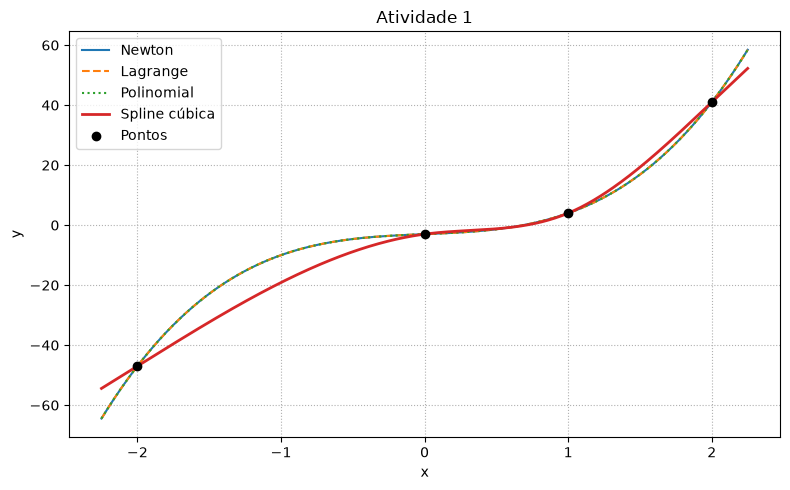

In [2]:
interpolar(
    [-2, 0, 1, 2],
    [-47, -3, 4, 41],
    [-1, 0.5, 1.5],
    titulo="Atividade 1",
)

## Atividade 2
Encontre o polinômio interpolador para o conjunto de pontos $[(-1, 1.25); (0.5, 0.5); (1, 1.25); (1.25, 1.8125)]$, utilizando os métodos de Newton, Lagrange, polinomial e spline cúbica. Quais valores para x $[-0.5; 0; 0.25]$. Desenhe um gráfico com as funções econtradas numericamente.

**Resposta esperada:**

$$
f(x) = 0.25 + x^2 \tag{polinomial}
$$

**Resultados:**

$$x = -0.5:\quad \text{Newton} = \text{Lagrange} = \text{polinomial} = 0.5,\quad \text{Spline} \approx 0.5$$

$$x = 0:\quad \text{Newton} = \text{Lagrange} = \text{polinomial} = 0.25,\quad \text{Spline} \approx 0.25$$

$$x = 0.25:\quad \text{Newton} = \text{Lagrange} = \text{polinomial} = 0.3125,\quad \text{Spline} \approx 0.3125$$

## Atividade 3
A medição de alguns pontos de uma curva de saturação magnética, num processo de desmagnetização do ferrite $MnZn_3C_{15}$ é:

(a) Utilizando os métodos de Newton, Lagrange, polinomial e spline cúbica. Qual valor da indução magnética $(mT)$ para $H = 0 A/m$. Desenhe um gráfico com as funções econtradas numericamente.

$$
\begin{array}{c|cccc}
\text{H (A/m)} & -50 & -5 & 5 & 75 \\ \hline
\text{B (mT)} & -300 & -50 & 180 & 350
\end{array}
$$

**Resultado:**

$$H=0:\quad \text{Newton}=\text{Lagrange}=\text{Polinômio}= \mathbf{62.813852}\ \text{mT},\quad \text{Spline} \approx \mathbf{63.801020}\ \text{mT}$$

(b) Utilizando os métodos de Newton, Lagrange, polinomial e spline cúbica. Qual valor do campo magnético $(A/m)$ para $T = 8.5s$. Desenhe um gráfico com as funções econtradas numericamente.

$$
\begin{array}{c|ccccccccccc}
\text{T (s)} & 0 & 1 & 2 & 3 & 4 & 5 & 6 & 7 & 8 & 9 & 10 \\ \hline
\text{H (A/m)} & 80 & -60 & 40 & -30 & 20 & -10 & 5 & -2.5 & 1.25 & -0.625 & 0.3125
\end{array}
$$

**Resultado:**

$$T=8.5:\quad \text{Newton}=\text{Lagrange}=\text{Polinômio}= \mathbf{47.211610}\ \text{A/m},\quad \text{Spline} \approx \mathbf{1.057374}\ \text{A/m}$$

Os métodos de **Newton**, **Lagrange** e **Polinômio** geram o mesmo polinômio de grau $10$, o que provoca **oscilações acentuadas**, fenômeno conhecido como *Runge*. Assim, o valor interpolado se afasta dos vizinhos $H(8)=1.25$ e $H(9)=-0.625$. Já a **spline cúbica natural**, por ser uma aproximação **local e suave**, fornece resultados mais consistentes e fisicamente plausíveis entre os pontos.

Newton: [-4.5950000e-03  8.7446000e-02  2.3114863e+01  6.2813853e+01]
  f([0.]) = [62.81385281]
Lagrange: [-4.5950000e-03  8.7446000e-02  2.3114863e+01  6.2813853e+01]
  f([0.]) = [62.81385281]
Polinomial: [-4.5950000e-03  8.7446000e-02  2.3114863e+01  6.2813853e+01]
  f([0.]) = [62.81385281]
Spline cúbica: f([0.]) = [63.80102041]


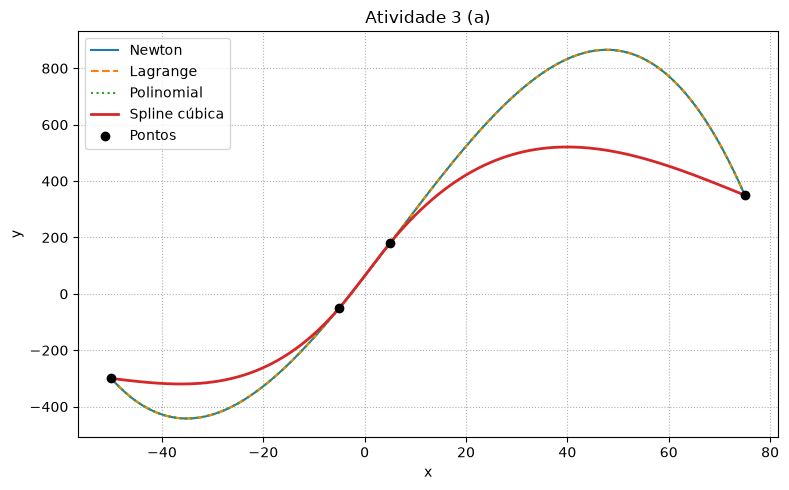

Newton: [ 3.91700000e-03 -2.00726000e-01  4.42458500e+00 -5.48450910e+01
  4.19307749e+02 -2.03834296e+03  6.25321986e+03 -1.15618984e+04
  1.15522626e+04 -4.71393155e+03  8.00000000e+01]
  f([8.5]) = [47.21161005]
Lagrange: [ 3.91700000e-03 -2.00726000e-01  4.42458500e+00 -5.48450910e+01
  4.19307749e+02 -2.03834296e+03  6.25321986e+03 -1.15618984e+04
  1.15522626e+04 -4.71393155e+03  8.00000000e+01]
  f([8.5]) = [47.21161009]
Polinomial: [ 3.91700000e-03 -2.00726000e-01  4.42458500e+00 -5.48450910e+01
  4.19307749e+02 -2.03834296e+03  6.25321986e+03 -1.15618984e+04
  1.15522626e+04 -4.71393155e+03  8.00000000e+01]
  f([8.5]) = [47.21161007]
Spline cúbica: f([8.5]) = [1.05737357]


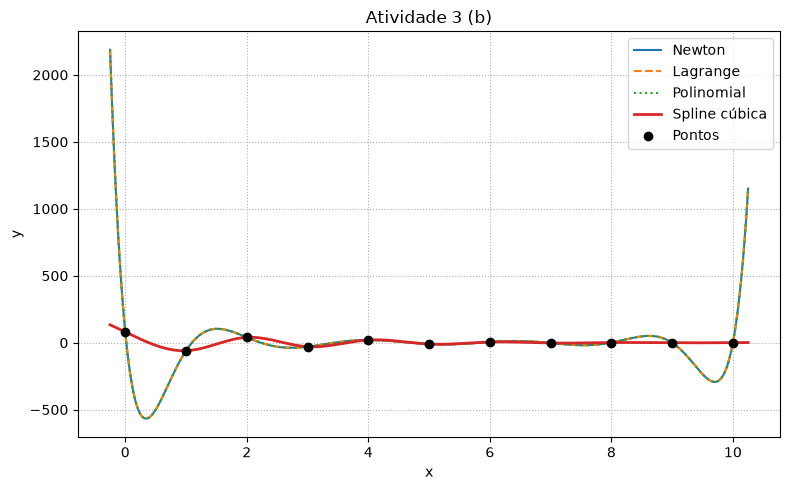

In [4]:
interpolar(
    [-50, -5, 5, 75],
    [-300, -50, 180, 350],
    [0],
    titulo="Atividade 3 (a)",
)

interpolar(
    np.arange(11),
    [80, -60, 40, -30, 20, -10, 5, -2.5, 1.25, -0.625, 0.3125],
    [8.5],
    titulo="Atividade 3 (b)",
)

## Versionando o código

Submeta a branch para o servidor:

```bash
git add .
git commit -m "Semana 9"
git push origin semana9
```